# Consonant inventory of a text (Kokoro tokens)

1. **Text → tokens:** the same G2P Kokoro uses (`text_to_ipa_chunks`), plus the token ids the model receives.
2. **Tokens → phonemes:** stress marks are removed, diacritics (ʰ ʲ ː) are attached to their consonant,
   affricates (tʃ, ts, dʒ, dz) become one phoneme, and geminates (tː, ɲɲ, Kokoro's `S` = sː) are recognised.
3. **Measure and plot:** top consonants, consonant classes (manner), position in the word, and geminates.

Vowels are kept in the table (so the share of consonants can be computed) but every count and plot uses consonants only.

In [1]:
from functions import *          # text_to_ipa_chunks, check_ipa, VOCAB, CONSONANTS, VOWELS, SKIP, BOUNDARY ...
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

c:\Users\utente\anaconda3\envs\koko\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
c:\Users\utente\anaconda3\envs\koko\Lib\site-packages\torch\nn\modules\rnn.py:123: UserWarning: dropout option adds dropout after all but last recurrent layer, so non-zero dropout expects num_layers greater than 1, but got dropout=0.2 and num_layers=1
  warnings.warn(
c:\Users\utente\anaconda3\envs\koko\Lib\site-packages\torch\nn\utils\weight_norm.py:143: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


## 1. Settings

| setting | meaning |
|---|---|
| `text` | your text (or read it from a file, see the comment) |
| `TOP_N` | how many consonants to show in the plots |
| `merge_affricates` | `True`: tʃ / ts / dʒ / dz count as **one** phoneme. `False`: as t + ʃ etc. |
| `geminates` | `"one"`: tː counts as one t. `"two"`: counts as two t's. `"separate"`: tː is its own phoneme |
| `keep_diacritics` | `True`: tʲ and t are different phonemes. `False`: tʲ counts as t |
| `include_glides` | count j, w as consonants |

In [2]:
# text = '''Il gatto dorme sotto il ramo verde. Maria compra il pane fresco ogni mattina.
# Il treno parte alle otto di sera. Mio fratello studia la storia a Roma.'''
text = Path("story2_new.txt").read_text(encoding="utf-8")

TOP_N            = 15
merge_affricates = True
geminates        = "one"        # "one" | "two" | "separate"
keep_diacritics  = True
include_glides   = True

out_dir = Path("consonant_out"); out_dir.mkdir(exist_ok=True)

## 2. Text → Kokoro tokens

`text_to_ipa_chunks` gives one IPA string per sentence, exactly what the model would read.
`check_ipa` shows the token ids and warns if any character is not in Kokoro's vocabulary (it would be dropped).

In [3]:
chunks = text_to_ipa_chunks(text)
for i, ps in enumerate(chunks):
    print(f"[{i}] {ps}")
print()
check_ipa(chunks);

[0] ʤˈulia bˈaSɪ diriʤˈɛva da ʧˈinkwe ˈannɪ il pˈikːolo ʊffˈiʧo postˈale dɪ kolleˈardo, ʊn paˈeze dɪ kollˈina ʧirkondˈato da bˈoskɪ e da kˈampɪ dɪ ɡrˈano.
[1] lʊffˈiʧo sɪ trovˈava al pjˈano tˈɛrɾa dɪ ʊn edifˈiʧo ʤˈallo, prˈɔprio dɪ frˈonte ˌalla kjˈɛza e akːˈanto allˈunika farmaʧˈiːa del paˈeze.
[2] kolleˈardo avˌeva ʧˈirka dʊemˈila abitˈantɪ, e kwˈazɪ tˈutːɪ paSˈavano dallʊffˈiʧo postˈale almˈeno ˌʊna vˈɔlta al mˈɛze.
[3] ˌɛra ˌʊna stˈanʦa lʊminˈoza, kon dˈue sportˈɛllɪ, ˌʊna fˈila dɪ sˈedje per latːˈeza e ʊn pˈikːolo maɡaʣːˈino djˈɛtro ˌʊna pˈɔrta dɪ vˈetro.
[4] nel maɡaʣːˈino sɪ konservˈavano i pˈakːɪ ke i korɾiˈɛrɪ non riʊʃˈivano a konseɲˈare, perkˌe le persˈone non ˈɛrano a kˈaza.
[5] il lavˈɔro dɪ ʤˈulia konsistˈɛva nel servˈire i kliˈɛntɪ, nel kontrollˈare i kˈontɪ e nellorɡaniʣːˈare le konsˈeɲɲe kon le dˈitːe estˈɛrne.
[6] ˌoɲɲɪ matːˈina arɾivˈava ˌalle ˈɔtːo mˈeno ʊn kwˈarto, aʧːendˈɛva i kompjˈuter, aprˈiva la kaSafˈɔrte e prepaɾˈava i mˈɔdʊlɪ per la ʤornˈata.
[7] lʊffˈiʧo ap

In [4]:
# every token as a row: chunk, position, character, token id, kind
def token_kind(c):
    if c in VOWELS: return "vowel"
    if c in CONSONANTS: return "consonant"
    if c in SKIP: return "stress/diacritic"
    if c == " ": return "space"
    if c in BOUNDARY: return "punctuation"
    return "other"

tokens = pd.DataFrame([{"chunk": ci, "pos": i, "char": c, "id": VOCAB.get(c), "kind": token_kind(c)}
                       for ci, ps in enumerate(chunks) for i, c in enumerate(ps)])
print(f"{len(tokens)} tokens in {len(chunks)} chunks")
display(tokens["kind"].value_counts().to_frame("tokens"))
tokens.head(20)

14388 tokens in 106 chunks


,tokens
kind,
consonant,5455
vowel,4844
space,2099
stress/diacritic,1735
punctuation,255


,chunk,pos,char,id,kind
0,0,0,ʤ,82,consonant
1,0,1,ˈ,156,stress/diacritic
2,0,2,u,63,vowel
3,0,3,l,54,consonant
4,0,4,i,51,vowel
5,0,5,a,43,vowel
6,0,6,,16,space
7,0,7,b,44,consonant
8,0,8,ˈ,156,stress/diacritic
9,0,9,a,43,vowel


## 3. Tokens → phonemes

| function | what it does |
|---|---|
| `segment(ps)` | Walks one IPA string and returns one record per phoneme: the base symbol, its diacritics (ʰ ʲ ̃), whether it is long (ː), its word, and whether it is a consonant. Stress marks are skipped; affricate pairs are joined. |
| `merge_geminates(rows)` | Two identical consonants next to each other in the same word (ɲɲ) become one long consonant, the same as tː. A stop before its own affricate (d + dʒ in *oggi*, t + ts in *pazzo*) becomes a long affricate. |
| `add_position(rows)` | Marks each phoneme as word-initial, medial or final. |
| `manner(ph)` | Consonant class: stop, fricative, affricate, nasal, lateral, rhotic, glide. |
| `label(row)` | The name a phoneme is counted under, following the settings above. |

In [5]:
AFFRICATES_2 = {"tʃ", "ts", "dʒ", "dz"}
MODS = {"ʰ", "ʲ", "̃"}                       # attach to the phoneme before them
LENGTH = "ː"

MANNER = {
    "stop":      set("pbtdkɡgcɟqʔʈɖ"),
    "fricative": set("fvszʃʒθðxɣχʁhçʝɕβɸʂ"),
    "affricate": {"ʦ", "ʣ", "ʧ", "ʤ", "ʨ", "ʥ", "ꭧ"} | AFFRICATES_2,
    "nasal":     set("mnɲŋɳɴ"),
    "lateral":   set("lʎ"),
    "rhotic":    set("rɾɹɻɽ"),
    "glide":     set("jwɥɰʋ"),
}
def manner(ph):
    for k, v in MANNER.items():
        if ph in v:
            return k
    return "other"

def segment(ps, chunk=0):
    rows, word, i, gap = [], -1, 0, True
    while i < len(ps):
        c = ps[i]
        if c in BOUNDARY:
            gap = True; i += 1; continue
        if gap:                                   # first char of a new word
            word += 1; gap = False
        if c in ("ˈ", "ˌ") or c not in (VOWELS | CONSONANTS):
            i += 1; continue                      # stress marks, tone arrows, unknown
        base, j = c, i + 1
        if c == "S":                              # misaki: geminate s written as one token
            base, long_ = "s", True
        else:
            long_ = False
        if merge_affricates and ps[i:i + 2] in AFFRICATES_2:
            base, j = ps[i:i + 2], i + 2
        mods = ""
        while j < len(ps) and (ps[j] in MODS or ps[j] == LENGTH):
            if ps[j] == LENGTH: long_ = True
            else: mods += ps[j]
            j += 1
        is_cons = base in CONSONANTS or base in AFFRICATES_2
        rows.append({"chunk": chunk, "word": word, "base": base, "mods": mods, "long": long_,
                     "consonant": is_cons})
        i = j
    return rows

def merge_geminates(rows):
    out = []
    for r in rows:
        p = out[-1] if out else None
        if (p and r["consonant"] and p["consonant"] and p["chunk"] == r["chunk"]
                and p["word"] == r["word"] and p["base"] == r["base"] and p["mods"] == r["mods"]
                and not p["long"]):
            p["long"] = True                      # ɲɲ -> ɲː
            continue
        if (p and r["consonant"] and p["chunk"] == r["chunk"] and p["word"] == r["word"]
                and r["base"] in AFFRICATES_2 and p["base"] == r["base"][0] and not p["mods"]):
            out[-1] = dict(r, long=True)          # d + dʒ -> dʒː,  t + ts -> tsː
            continue
        out.append(dict(r))
    return out

def add_position(rows):
    for k, r in enumerate(rows):
        same = lambda q: 0 <= q < len(rows) and rows[q]["chunk"] == r["chunk"] and rows[q]["word"] == r["word"]
        first, last = not same(k - 1), not same(k + 1)
        r["position"] = "initial" if first else ("final" if last else "medial")
    return rows

def label(r):
    s = r["base"] + (r["mods"] if keep_diacritics else "")
    if geminates == "separate" and r["long"]:
        s += LENGTH
    return s

rows = []
for ci, ps in enumerate(chunks):
    rows += segment(ps, ci)
rows = add_position(merge_geminates(rows))
ph = pd.DataFrame(rows)
ph["phoneme"] = ph.apply(label, axis=1)
ph["manner"] = ph["base"].map(manner)
ph["weight"] = np.where((geminates == "two") & ph["long"], 2, 1)   # "two": a geminate counts twice

cons = ph[ph["consonant"] & (include_glides | (ph["manner"] != "glide"))]
n_all = ph["weight"].sum(); n_cons = cons["weight"].sum()
print(f"phonemes: {n_all}   consonants: {n_cons} ({100*n_cons/n_all:.1f}%)   "
      f"vowels: {ph.loc[~ph['consonant'], 'weight'].sum()}   different consonants: {cons['phoneme'].nunique()}")
ph.head(20)

phonemes: 10103   consonants: 5259 (52.1%)   vowels: 4844   different consonants: 25


,chunk,word,base,mods,long,consonant,position,phoneme,manner,weight
0,0,0,ʤ,,False,True,initial,ʤ,affricate,1
1,0,0,u,,False,False,medial,u,other,1
2,0,0,l,,False,True,medial,l,lateral,1
3,0,0,i,,False,False,medial,i,other,1
4,0,0,a,,False,False,final,a,other,1
5,0,1,b,,False,True,initial,b,stop,1
6,0,1,a,,False,False,medial,a,other,1
7,0,1,s,,True,True,medial,s,fricative,1
8,0,1,ɪ,,False,False,final,ɪ,other,1
9,0,2,d,,False,True,initial,d,stop,1


## 4. Top consonants

,count,percent,manner
phoneme,,,
n,745,14.2,nasal
r,630,12.0,rhotic
t,580,11.0,stop
l,578,11.0,lateral
k,449,8.5,stop
d,341,6.5,stop
s,323,6.1,fricative
p,312,5.9,stop
m,274,5.2,nasal


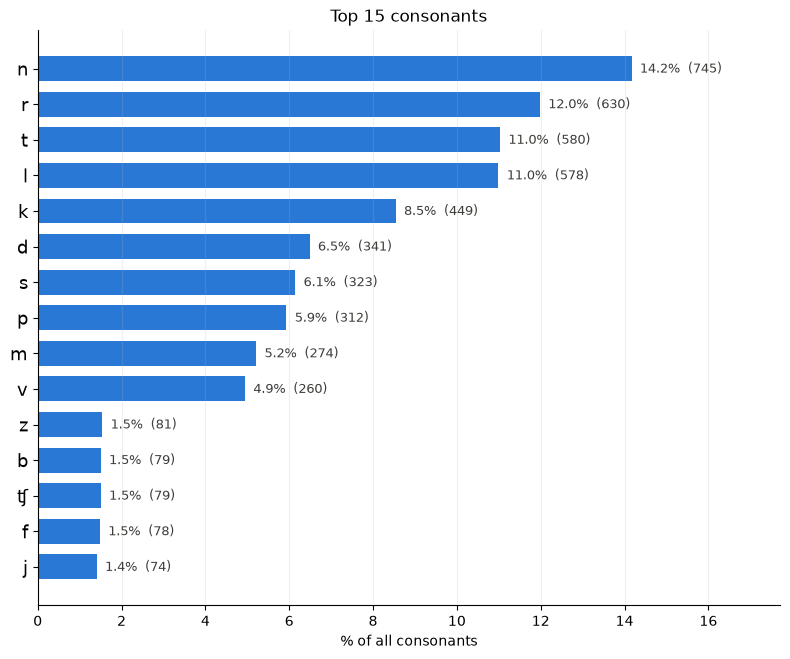

In [6]:
counts = (cons.groupby("phoneme")["weight"].sum().sort_values(ascending=False)
              .rename("count").to_frame())
counts["percent"] = 100 * counts["count"] / n_cons
counts["manner"] = [manner(cons.loc[cons["phoneme"] == p, "base"].iloc[0]) for p in counts.index]
counts.to_csv(out_dir / "consonant_counts.csv")
display(counts.round(1))

top = counts.head(TOP_N)[::-1]
fig, ax = plt.subplots(figsize=(8, 0.38 * len(top) + 1))
bars = ax.barh(top.index, top["percent"], color="#2a78d6", height=0.7)
for b, n in zip(bars, top["count"]):
    ax.text(b.get_width() + 0.2, b.get_y() + b.get_height() / 2, f"{b.get_width():.1f}%  ({n})",
            va="center", fontsize=9, color="#3d3d3a")
ax.set_xlabel("% of all consonants"); ax.set_title(f"Top {len(top)} consonants")
ax.tick_params(axis="y", labelsize=13)
for s in ("top", "right"): ax.spines[s].set_visible(False)
ax.grid(axis="x", alpha=.2); ax.set_xlim(0, top["percent"].max() * 1.25)
plt.tight_layout(); plt.savefig(out_dir / "top_consonants.png", dpi=150); plt.show()

## 5. Consonant classes (manner of articulation)

In [ ]:
by_manner = cons.groupby("manner")["weight"].sum().sort_values(ascending=False)
pct = 100 * by_manner / n_cons
display(pd.DataFrame({"count": by_manner, "percent": pct.round(1)}))

fig, ax = plt.subplots(figsize=(8, 0.45 * len(pct) + 1))
bars = ax.barh(pct.index[::-1], pct.values[::-1], color="#2a78d6", height=0.7)
for b, n in zip(bars, by_manner.values[::-1]):
    ax.text(b.get_width() + 0.3, b.get_y() + b.get_height() / 2, f"{b.get_width():.1f}%  ({n})",
            va="center", fontsize=9, color="#3d3d3a")
ax.set_xlabel("% of all consonants"); ax.set_title("Consonants by manner")
for s in ("top", "right"): ax.spines[s].set_visible(False)
ax.grid(axis="x", alpha=.2); ax.set_xlim(0, pct.max() * 1.25)
plt.tight_layout(); plt.savefig(out_dir / "consonant_manner.png", dpi=150); plt.show()

## 6. Where in the word? (top consonants × position)

Each row shows how one consonant's occurrences split over word-initial, medial and final position (rows sum to 100%).

position,initial,medial,final,total
phoneme,,,,
n,104,542,102,748
l,139,366,131,636
t,99,517,0,616
r,71,516,27,614
s,261,151,0,412
k,206,194,0,400
d,221,122,4,347
p,198,117,0,315
m,72,196,0,268


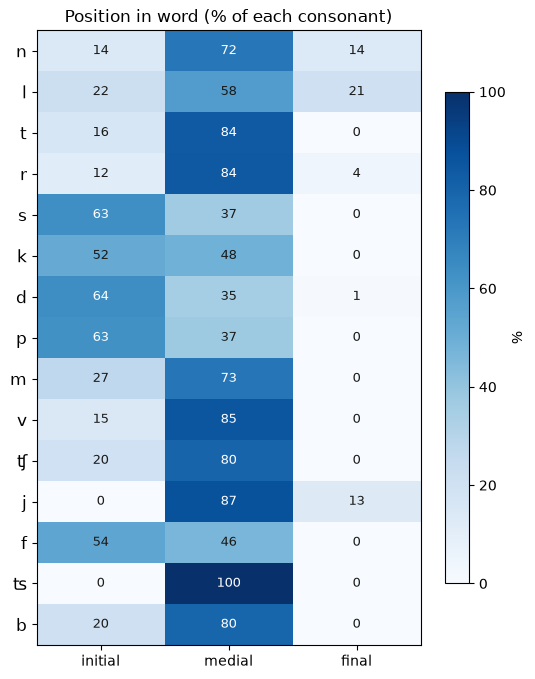

In [7]:
order = counts.head(TOP_N).index
pos = (cons[cons["phoneme"].isin(order)]
       .pivot_table(index="phoneme", columns="position", values="weight", aggfunc="sum", fill_value=0)
       .reindex(index=order, columns=["initial", "medial", "final"], fill_value=0))
pos_pct = 100 * pos.div(pos.sum(axis=1), axis=0)
display(pos.assign(total=pos.sum(axis=1)))

fig, ax = plt.subplots(figsize=(5.5, 0.38 * len(order) + 1.2))
im = ax.imshow(pos_pct.values, cmap="Blues", vmin=0, vmax=100, aspect="auto")
ax.set_xticks(range(3), pos_pct.columns); ax.set_yticks(range(len(order)), order, fontsize=12)
for i in range(pos_pct.shape[0]):
    for j in range(3):
        v = pos_pct.values[i, j]
        ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=9,
                color="white" if v > 60 else "#1a1a19")
ax.set_title("Position in word (% of each consonant)")
fig.colorbar(im, ax=ax, label="%", shrink=0.8)
plt.tight_layout(); plt.savefig(out_dir / "consonant_position.png", dpi=150); plt.show()

## 7. Geminates (long consonants)

In [ ]:
gem = cons[cons["long"]]
g = gem.groupby("base").size().sort_values(ascending=False).rename("geminates").to_frame()
g["of all occurrences %"] = [100 * g.loc[b, "geminates"] / (cons["base"] == b).sum() for b in g.index]
print(f"{len(gem)} geminate consonants ({100*len(gem)/len(cons):.1f}% of consonant tokens)")
g.round(1)

## 8. Find where a consonant occurs

Lists every word (as IPA) containing the phoneme, so you can check that the counting is right.

In [10]:
FIND = "z"

def ipa_words(ps):
    return [w for w in re.split(r"[ " + re.escape("".join(BOUNDARY - {' '})) + r"]+", ps) if w]

hits = cons[cons["phoneme"] == FIND][["chunk", "word"]].drop_duplicates()
words = {ci: ipa_words(ps) for ci, ps in enumerate(chunks)}
print(f"'{FIND}': {cons.loc[cons['phoneme'] == FIND, 'weight'].sum()} occurrences in {len(hits)} words")
for ci, w in hits.itertuples(index=False):
    print(f"  chunk {ci}: {words[ci][w] if w < len(words[ci]) else '?'}")

'z': 38 occurrences in 38 words
  chunk 7: silenʦjˈozo
  chunk 8: zvʊotˈavano
  chunk 10: preʧiziˈone
  chunk 19: kjˈuze
  chunk 21: allimprovvˈizo
  chunk 21: silenʦjˈɔza
  chunk 26: prˈezo
  chunk 27: kwˈazɪ
  chunk 28: kozˈi
  chunk 28: silenʦjˈɔza
  chunk 33: kˈaza
  chunk 34: kˈazo
  chunk 34: kˈaza
  chunk 37: kwˈazɪ
  chunk 39: deʧˈizo
  chunk 39: kˈɔza
  chunk 46: kwˈazɪ
  chunk 47: ʊzˈato
  chunk 49: ʃˈezo
  chunk 49: prezˈɛnʦa
  chunk 53: kwˈazɪ
  chunk 55: kwalkˈɔza
  chunk 61: kˈazo
  chunk 63: bizˈoɲɲo
  chunk 66: kˈaza
  chunk 66: deʧˈizo
  chunk 66: preʧˈizo
  chunk 68: ʊzˈare
  chunk 69: ezˈatːo
  chunk 70: apːˈezo
  chunk 72: kjˈuzɪ
  chunk 77: silenʦjˈɔza
  chunk 79: rizʊltˈato
  chunk 89: ezatːamˈente
  chunk 93: rizˈolvere
  chunk 95: bizˈoɲɲo
  chunk 101: kˈɔze
  chunk 102: kozˈi
